## Cal Poly, San Luis Obispo, Fall 2026
## DATA 3301: Introduction to Data Science

# Group Project: Data Notebook

## Before You Do Anything Else!!!

**At least one person** should save a copy of this notebook to their Google Drive (File > Save a copy in Drive) and share it with the group (Share, top right). Colab does not merge edits well, so avoid having two people run or edit the notebook at the same time.

**Project title:** Octagon Analytics

**Group members:** Brandon, Noah, Cis, David

**Our question (one sentence):** Can we predict who will win a UFC fight based on main fighter attributes?


**Data source(s), with links:** https://github.com/jansen88/ufc-data/tree/master/data

**One row of our data represents:** A fighter and their main stats/metrics

# How to use this notebook

This is a workspace, not a lab. It walks through the order of work from Labs 1 to 5: **load → prepare → describe one variable at a time → describe pairs → compute metrics → model**. Each part has a short prompt, a small reference table, and empty cells. Add as many cells as you need, and delete prompts that don't apply to your data.

* Make every chart with **Altair**, and make it **professional-looking**: labeled axes with units, a title, sensible scales, and readable legends.
* End each code cell by **displaying** what you computed, so you (and I) can review it.
* Put written answers in the **Notes** text cells, not in code comments.

### Where to find help

* **Data frames, joins, unions, grouping:** DS02, DS03, LN04, Lab 1
* **Categorical vs. numerical variables:** LN05, DS04
* **Altair:** DS06, DS07, and Lab 3's Altair How-To Guide (G0 to G11)
* **Quantitative variables, distance and similarity:** LN07, LN08, DS08
* **Text data (bag of words, TF-IDF):** LN09, LN10, DS09
* **One-hot encoding, KNN, linear regression:** LN11, LN12, DS11, DS12, Lab 4
* **Evaluation and model selection:** LN13, LN14, DS13, DS14, Lab 5

In [36]:
import pandas as pd
import numpy as np
import altair as alt

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold

### Add any other import statements you need below

import re
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns

# Part 1: Load Your Data

Four common ways to get data into a DataFrame. They are **examples only** (commented out). Copy the one you need into the cell at the end of Part 1, uncomment it, and fill in your own file names, URLs, and IDs.

**A. A file you have (CSV, Excel, ...)**

In [ ]:
# 1. Click the folder icon in the left sidebar and drag your file in.
#    Files uploaded this way are DELETED when the session ends, so you'd re-upload every time.
# 2. Read it with pandas:
#
# df = pd.read_csv("my_data.csv")
# df = pd.read_excel("my_data.xlsx", sheet_name=0)    # 0 = first tab; or the tab's name
# df = pd.read_csv("my_data.tsv", sep="\t")           # tab-separated
#
# A file that is already online (a raw GitHub link, as in Lab 5) works the same way:
# df = pd.read_csv("https://raw.githubusercontent.com/<user>/<repo>/main/my_data.csv")
#
# To keep files between sessions, put them in Google Drive and mount it.
# (If a groupmate shared the folder with you, first right-click it in Drive > Organize > Add shortcut to My Drive.)
# from google.colab import drive
# drive.mount("/content/drive")
# df = pd.read_csv("/content/drive/MyDrive/<folder>/my_data.csv")

**B. A web API that returns JSON**

In [ ]:
# Read the API's documentation for: the URL (the "endpoint"), its query parameters, and whether it needs a key.
#
# url = "https://api.example.com/v1/records?city=San%20Luis%20Obispo&limit=1000"
# raw = pd.read_json(url, typ="series")     # the whole response
# raw.index                                 # what's inside? the records are usually under one key
# df = pd.json_normalize(raw["results"])    # one row per record; nested fields become "a.b" columns
#
# If the response is already a plain list of records, pd.read_json(url) gives you a DataFrame directly.
#
# API keys: never paste a key into the notebook (you will share it). Click the key icon in the
# left sidebar ("Secrets"), add it as MY_API_KEY, and allow notebook access. Then:
# from google.colab import userdata
# key = userdata.get("MY_API_KEY")
# df = pd.read_json(f"https://api.example.com/v1/records?api_key={key}")                      # key in the URL, or
# df = pd.read_json("https://api.example.com/v1/records", storage_options={"Authorization": f"Bearer {key}"})   # key in a header
#
# Many APIs return one "page" (say, 100 records) per request; check the docs for limit/offset or page parameters.
# Save what you pulled so you don't hit the API on every run:
# df.to_csv("my_data.csv", index=False)

**C. A Google Sheet your group edits together**

In [ ]:
# In the sheet: Share > General access > "Anyone with the link" (Viewer). Then copy the IDs from its URL:
#   https://docs.google.com/spreadsheets/d/<SHEET_ID>/edit#gid=<TAB_ID>
#
# sheet_id = "<SHEET_ID>"
# tab_id = 0                                # the gid of the tab you want; the first tab is usually 0
# df = pd.read_csv(f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={tab_id}")

**D. A table on a web page (Wikipedia, a government site, ...)**

In [ ]:
# read_html returns a LIST with every <table> on the page. Find the one you want.
#
# tables = pd.read_html("https://en.wikipedia.org/wiki/<Page_Title>")
# len(tables)
# df = tables[0]
#
# Narrow it down with text that appears in your table:      pd.read_html(url, match="Population")
# If the site refuses the request (HTTP 403 Forbidden), add:  storage_options={"User-Agent": "Mozilla/5.0"}

**Your data:** load every table your project needs.

In [21]:
# Load your data here

SC = pd.read_csv(
    "https://raw.githubusercontent.com/Octagon-Analytics/Octagon_Analytics/main/SCORECARDS.csv",
    sep=";"
)
event_df = pd.read_csv(
    "https://raw.githubusercontent.com/Octagon-Analytics/Octagon_Analytics/main/events_raw.csv"
)
fighter_df = pd.read_csv(
    "https://raw.githubusercontent.com/Octagon-Analytics/Octagon_Analytics/main/fighters_raw.csv"
)
stats_df = pd.read_csv(
    "https://raw.githubusercontent.com/Octagon-Analytics/Octagon_Analytics/main/merged_stats_n_scorecards.csv"
)
odds_df = pd.read_csv(
    "https://raw.githubusercontent.com/Octagon-Analytics/Octagon_Analytics/main/odds_raw.csv"
)

# Part 2: Prepare Your Data

Get to **one DataFrame where each row is one observation** (your answer to "one row represents...") and each column is one variable you will use.

| You want to... | Code |
|---|---|
| look at it | `df.shape`, `df.dtypes`, `df.head()`, `df.isna().sum()` |
| fix a type | `pd.to_numeric(df["col"], errors="coerce")`, `pd.to_datetime(df["col"])`, `df["col"].astype("category")` |
| keep the columns you need | `df[["col1", "col2"]]`, `df.rename(columns={...})` |
| keep the rows you need | `df.query("year >= 2020")`, `df.dropna(subset=[...])` |
| combine tables | `df1.merge(df2, on="key", how="inner")` (join), `pd.concat([df1, df2])` (union) |
| change what a row is | `df.groupby("col").agg(...)`, `df.melt(...)`, `df.pivot_table(...)` |

In [6]:
# 2.1 Inspect
SC

,red_fighter_name,blue_fighter_name,event_date,red_fighter_total_pts,blue_fighter_total_pts
0,POLIANA BOTELHO,LUANA CAROLINA,01/05/2021,29 28 28,28 29 29
1,KAI KAMAKA,TJ BROWN,01/05/2021,28 28 30,29 29 27
2,MERAB DVALISHVILI,CODY STAMANN,01/05/2021,30 29 29,27 28 28
3,RANDA MARKOS,LUANA PINHEIRO,01/05/2021,- - -,- - -
4,ANDREAS MICHAILIDIS,KB BHULLAR,01/05/2021,29 30 30,28 27 27
...,...,...,...,...,...
2246,MARIYA AGAPOVA,SHANA DOBSON,23/08/2020,10 10 10,9 9 9
2247,DANIEL RODRIGUEZ,DWIGHT GRANT,23/08/2020,- - -,- - -
2248,AMANDA LEMOS,MIZUKI,23/08/2020,30 30 30,27 27 27
2249,IKE VILLANUEVA,JORDAN WRIGHT,23/08/2020,- - -,- - -


In [7]:
event_df

,event_name,event_date,event_location,Weight class,fighter1,fighter2,outcome,Kd,Str,Td,Sub,Method,Round,Time,timestamp
0,UFC Fight Night: Grasso vs. Shevchenko 2,September 16 2023,"Las Vegas, Nevada, USA",Women's Flyweight,Alexa Grasso,Valentina Shevchenko,Draw,1 0,84 80,1 4,1 1,S-DEC,5,5:00,2023-09-21 02:02:55.178363
1,UFC Fight Night: Grasso vs. Shevchenko 2,September 16 2023,"Las Vegas, Nevada, USA",Welterweight,Jack Della Maddalena,Kevin Holland,fighter1,0 0,105 127,0 0,0 0,S-DEC,3,5:00,2023-09-21 02:02:55.178363
2,UFC Fight Night: Grasso vs. Shevchenko 2,September 16 2023,"Las Vegas, Nevada, USA",Bantamweight,Raul Rosas Jr.,Terrence Mitchell,fighter1,1 0,18 6,0 0,0 0,KO/TKO Punches,1,0:54,2023-09-21 02:02:55.178363
3,UFC Fight Night: Grasso vs. Shevchenko 2,September 16 2023,"Las Vegas, Nevada, USA",Lightweight,Daniel Zellhuber,Christos Giagos,fighter1,0 0,36 38,0 0,1 0,SUB Anaconda Choke,2,3:26,2023-09-21 02:02:55.178363
4,UFC Fight Night: Grasso vs. Shevchenko 2,September 16 2023,"Las Vegas, Nevada, USA",Featherweight,Kyle Nelson,Fernando Padilla,fighter1,0 0,82 72,0 0,0 0,U-DEC,3,5:00,2023-09-21 02:02:55.178363
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7335,UFC 2: No Way Out,March 11 1994,"Denver, Colorado, USA",Open Weight,Orlando Wiet,Robert Lucarelli,fighter1,0 0,8 2,0 1,0 1,KO/TKO,1,2:50,2023-09-21 02:02:55.178363
7336,UFC 2: No Way Out,March 11 1994,"Denver, Colorado, USA",Open Weight,Frank Hamaker,Thaddeus Luster,fighter1,0 0,2 0,1 0,3 0,SUB Keylock,1,4:52,2023-09-21 02:02:55.178363
7337,UFC 2: No Way Out,March 11 1994,"Denver, Colorado, USA",Open Weight,Johnny Rhodes,David Levicki,fighter1,0 0,11 4,1 0,0 0,KO/TKO Punches,1,12:13,2023-09-21 02:02:55.178363
7338,UFC 2: No Way Out,March 11 1994,"Denver, Colorado, USA",Open Weight,Patrick Smith,Ray Wizard,fighter1,0 0,1 1,0 0,1 0,SUB Guillotine Choke,1,0:58,2023-09-21 02:02:55.178363


In [8]:
fighter_df

,name,fight_record,nickname,Height,Weight,Reach,STANCE,DOB,SLpM,Str.Acc.,SApM,Str.Def,TDAvg.,TDAcc.,TDDef.,Sub.Avg.,timestamp
0,Tom Aaron,5-3-0,NaN,--,155lbs.,--,NaN,"Jul13,1978",0.00,0%,0.00,0%,0.00,0%,0%,0.0,2023-09-20 21:50:56.958211
1,Danny Abbadi,4-6-0,The Assassin,"5'11""",155lbs.,--,Orthodox,"Jul03,1983",3.29,38%,4.41,57%,0.00,0%,77%,0.0,2023-09-20 21:50:56.958211
2,Nariman Abbasov,28-4-0,Bayraktar,"5'8""",155lbs.,"66""",Orthodox,"Feb01,1994",3.00,20%,5.67,46%,0.00,0%,66%,0.0,2023-09-20 21:50:56.958211
3,David Abbott,10-15-0,Tank,"6'0""",265lbs.,--,Switch,--,1.35,30%,3.55,38%,1.07,33%,66%,0.0,2023-09-20 21:50:56.958211
4,Hamdy Abdelwahab,5-0-0 (1 NC),The Hammer,"6'2""",264lbs.,"72""",Southpaw,"Jan22,1993",3.87,52%,3.13,59%,3.00,75%,0%,0.0,2023-09-20 21:50:56.958211
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4101,Dave Zitanick,5-7-0 (1 NC),NaN,--,170lbs.,--,NaN,"Mar05,1980",0.00,0%,0.00,0%,0.00,0%,0%,0.0,2023-09-20 21:50:56.958211
4102,Alex Zuniga,6-3-0,NaN,--,145lbs.,--,NaN,--,0.00,0%,0.00,0%,0.00,0%,0%,0.0,2023-09-20 21:50:56.958211
4103,George Zuniga,3-1-0,NaN,"5'9""",185lbs.,--,NaN,--,7.64,38%,5.45,37%,0.00,0%,100%,0.0,2023-09-20 21:50:56.958211
4104,Allan Zuniga,13-1-0,Tigre,"5'7""",155lbs.,"70""",Orthodox,"Apr04,1992",3.93,52%,1.80,61%,0.00,0%,57%,1.0,2023-09-20 21:50:56.958211


In [9]:
stats_df

,red_fighter_name,blue_fighter_name,event_date,red_fighter_nickname,blue_fighter_nickname,red_fighter_result,blue_fighter_result,fight_outcome,method,round,...,red_fighter_sig_str_leg_pct,blue_fighter_sig_str_leg_pct,red_fighter_sig_str_distance_pct,blue_fighter_sig_str_distance_pct,red_fighter_sig_str_clinch_pct,blue_fighter_sig_str_clinch_pct,red_fighter_sig_str_ground_pct,blue_fighter_sig_str_ground_pct,red_fighter_total_pts,blue_fighter_total_pts
0,ABDUL RAKHMAN YAKHYAEV,JULIUS WALKER,27/06/2026,The Hunter,Juice Box,W,L,red_win,KO/TKO,1,...,0.0,0.0,16.0,0.0,0.0,0.0,83.0,0.0,NaN,NaN
1,ABUS MAGOMEDOV,MICHAL OLEKSIEJCZUK,27/06/2026,NaN,Hussar,W,L,red_win,Submission,1,...,10.0,40.0,90.0,100.0,10.0,0.0,0.0,0.0,NaN,NaN
2,ASU ALMABAYEV,CHARLES JOHNSON,27/06/2026,Zulfikar,InnerG,W,L,red_win,Submission,3,...,21.0,38.0,64.0,85.0,3.0,14.0,32.0,0.0,NaN,NaN
3,BEKZAT ALMAKHAN,JEAN MATSUMOTO,27/06/2026,The Turan Warrior,NaN,L,W,blue_win,Decision - Unanimous,3,...,1.0,30.0,94.0,88.0,5.0,7.0,0.0,3.0,NaN,NaN
4,DANIIL DONCHENKO,THEODOR BERGGREN,27/06/2026,NaN,Simba,W,L,red_win,KO/TKO,2,...,40.0,4.0,85.0,86.0,14.0,13.0,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8732,ROYCE GRACIE,JASON DELUCIA,11/03/1994,NaN,NaN,W,L,red_win,Submission,1,...,33.0,0.0,33.0,0.0,34.0,0.0,33.0,0.0,NaN,NaN
8733,ROYCE GRACIE,MINOKI ICHIHARA,11/03/1994,NaN,NaN,W,L,red_win,Submission,1,...,100.0,0.0,100.0,0.0,0.0,0.0,0.0,100.0,NaN,NaN
8734,ROYCE GRACIE,PATRICK SMITH,11/03/1994,NaN,NaN,W,L,red_win,KO/TKO,1,...,25.0,0.0,0.0,0.0,25.0,100.0,75.0,0.0,NaN,NaN
8735,ROYCE GRACIE,REMCO PARDOEL,11/03/1994,NaN,Grizzly,W,L,red_win,Submission,1,...,33.0,0.0,33.0,0.0,34.0,0.0,33.0,0.0,NaN,NaN


In [10]:
odds_df

,link,date,event,fighter1,fighter2,fighter1_odds,fighter2_odds,result,timestamp
0,http://www.betmma.tips/mma_event_betting_histo...,16th Dec 23,UFC 296,Leon Edwards,Colby Covington,1.65,2.40,Leon Edwards,2023-12-28 11:40:25.898186
1,http://www.betmma.tips/mma_event_betting_histo...,16th Dec 23,UFC 296,Alexandre Pantoja,Brandon Royval,1.53,2.90,Alexandre Pantoja,2023-12-28 11:40:25.898186
2,http://www.betmma.tips/mma_event_betting_histo...,16th Dec 23,UFC 296,Shavkat Rakhmonov,Stephen Thompson,1.17,6.00,Shavkat Rakhmonov,2023-12-28 11:40:25.898186
3,http://www.betmma.tips/mma_event_betting_histo...,16th Dec 23,UFC 296,Paddy Pimblett,Tony Ferguson,1.33,3.95,Paddy Pimblett,2023-12-28 11:40:25.898186
4,http://www.betmma.tips/mma_event_betting_histo...,16th Dec 23,UFC 296,Bryce Mitchell,Josh Emmett,1.40,3.30,Josh Emmett,2023-12-28 11:40:25.898186
...,...,...,...,...,...,...,...,...,...
4447,http://www.betmma.tips/mma_event_betting_histo...,7th Nov 14,UFC Fight Night - Rockhold vs. Bisping,Dylan Andrews,Sam Alvey,1.61,2.50,Sam Alvey,2023-12-28 11:40:25.898186
4448,http://www.betmma.tips/mma_event_betting_histo...,7th Nov 14,UFC Fight Night - Rockhold vs. Bisping,Richie Vaculik,Louis Smolka,4.00,1.32,Louis Smolka,2023-12-28 11:40:25.898186
4449,http://www.betmma.tips/mma_event_betting_histo...,7th Nov 14,UFC Fight Night - Rockhold vs. Bisping,Vik Grujic,Chris Clements,1.75,2.27,Chris Clements,2023-12-28 11:40:25.898186
4450,http://www.betmma.tips/mma_event_betting_histo...,7th Nov 14,UFC Fight Night - Rockhold vs. Bisping,Daniel Kelly,Luke Zachrich,3.57,1.35,Daniel Kelly,2023-12-28 11:40:25.898186


In [30]:


def clean_name(x):
    """Standardize fighter names for reliable merges."""
    if pd.isna(x):
        return np.nan

    x = unicodedata.normalize("NFKD", str(x))
    x = "".join(char for char in x if not unicodedata.combining(char))
    x = re.sub(r"[^A-Za-z\s]", "", x)
    return re.sub(r"\s+", " ", x).strip().upper()

def clean_numeric(x):
    """Convert values such as '52%', '72"', '--', and plain numbers."""
    x = pd.Series(x, copy=False).astype("string")

    return pd.to_numeric(
        x.str.replace("%", "", regex=False)
         .str.replace("lbs.", "", regex=False)
         .str.replace('"', "", regex=False)
         .str.replace("--", "", regex=False)
         .str.strip(),
        errors="coerce"
    )

# Make copies so original imported data remains unchanged
events_clean = event_df.copy()
stats_clean = stats_df.copy()
fighters_clean = fighter_df.copy()
odds_clean = odds_df.copy()

# Standardize all column names
for df in [events_clean, stats_clean, fighters_clean, odds_clean]:
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
    )

In [31]:
# Select the dataframe containing detailed red/blue fight data
if {"red_fighter_name", "blue_fighter_name"}.issubset(events_clean.columns):
    fights = events_clean.copy()

elif {"red_fighter_name", "blue_fighter_name"}.issubset(stats_clean.columns):
    fights = stats_clean.copy()

else:
    raise ValueError(
        "Could not find red_fighter_name and blue_fighter_name "
        "in event_df or stats_df."
    )

# Ensure event dates are real dates
fights["event_date"] = pd.to_datetime(
    fights["event_date"],
    dayfirst=True,
    errors="coerce"
)

# Keep only completed fights with known date and winner/loser
fights = fights.dropna(
    subset=[
        "event_date",
        "red_fighter_name",
        "blue_fighter_name",
        "red_fighter_result",
        "blue_fighter_result"
    ]
).copy()

# Find stats available for both red and blue fighters
exclude_columns = {
    "red_fighter_name",
    "blue_fighter_name",
    "red_fighter_nickname",
    "blue_fighter_nickname",
    "red_fighter_result",
    "blue_fighter_result"
}

red_stat_cols = [
    col for col in fights.columns
    if col.startswith("red_fighter_") and col not in exclude_columns
]

stat_bases = []

for red_col in red_stat_cols:
    stat = red_col.replace("red_fighter_", "")
    blue_col = f"blue_fighter_{stat}"

    if blue_col in fights.columns:
        stat_bases.append(stat)

# Convert a fight into two fighter-level rows
red_df = pd.DataFrame({
    "fight_id": fights.index,
    "event_date": fights["event_date"],
    "fighter": fights["red_fighter_name"],
    "opponent": fights["blue_fighter_name"],
    "fighter_result": fights["red_fighter_result"],
    "corner": "red"
})

blue_df = pd.DataFrame({
    "fight_id": fights.index,
    "event_date": fights["event_date"],
    "fighter": fights["blue_fighter_name"],
    "opponent": fights["red_fighter_name"],
    "fighter_result": fights["blue_fighter_result"],
    "corner": "blue"
})

# Attach each fighter's same-fight raw stats temporarily.
# They will become lagged historical features in the next section.
for stat in stat_bases:
    red_df[stat] = fights[f"red_fighter_{stat}"].values
    blue_df[stat] = fights[f"blue_fighter_{stat}"].values

fighter_fights = pd.concat([red_df, blue_df], ignore_index=True)

fighter_fights["fighter_key"] = fighter_fights["fighter"].apply(clean_name)
fighter_fights["opponent_key"] = fighter_fights["opponent"].apply(clean_name)

# Target: fighter win = 1; fighter loss = 0
fighter_fights["won_fight"] = np.where(
    fighter_fights["fighter_result"].eq("W"), 1,
    np.where(fighter_fights["fighter_result"].eq("L"), 0, np.nan)
)

# Exclude draws, no contests, or missing fighter identity
fighter_fights = fighter_fights.dropna(
    subset=["fighter_key", "opponent_key", "event_date", "won_fight"]
).copy()

fighter_fights["won_fight"] = fighter_fights["won_fight"].astype(int)

# Convert raw stats to numbers.
# Fields formatted like "12 of 30" become separate landed and attempted columns.
usable_stat_cols = []

for stat in stat_bases:
    raw = fighter_fights[stat].astype("string")

    landed_attempted_mask = raw.str.match(
        r"^\s*\d+\s+of\s+\d+\s*$",
        na=False
    )

    if landed_attempted_mask.any():
        extracted = raw.str.extract(
            r"^\s*(\d+)\s+of\s+(\d+)\s*$"
        )

        landed_col = f"{stat}_landed"
        attempted_col = f"{stat}_attempted"

        fighter_fights[landed_col] = pd.to_numeric(
            extracted[0],
            errors="coerce"
        )

        fighter_fights[attempted_col] = pd.to_numeric(
            extracted[1],
            errors="coerce"
        )

        usable_stat_cols.extend([landed_col, attempted_col])

    else:
        fighter_fights[stat] = clean_numeric(fighter_fights[stat])
        usable_stat_cols.append(stat)

# Sort chronologically before creating any historical features
fighter_fights = fighter_fights.sort_values(
    ["fighter_key", "event_date", "fight_id"]
).reset_index(drop=True)

In [33]:
# ---------------------------------------------------
# Pre-fight record and historical performance features
# ---------------------------------------------------

fighter_fights["pre_fight_wins"] = (
    fighter_fights.groupby("fighter_key")["won_fight"]
    .transform(lambda x: x.shift().cumsum())
)

fighter_fights["pre_fight_losses"] = (
    fighter_fights.groupby("fighter_key")["won_fight"]
    .transform(lambda x: x.shift().eq(0).cumsum())
)

fighter_fights["pre_fight_total_bouts"] = (
    fighter_fights["pre_fight_wins"] +
    fighter_fights["pre_fight_losses"]
)

fighter_fights["pre_fight_win_pct"] = (
    fighter_fights["pre_fight_wins"] /
    fighter_fights["pre_fight_total_bouts"]
).fillna(0.50)

fighter_fights["last_3_win_pct"] = (
    fighter_fights.groupby("fighter_key")["won_fight"]
    .transform(lambda x: x.shift().rolling(3, min_periods=1).mean())
).fillna(0.50)

# Historical career average entering each fight.
# shift() prevents same-fight information leaking into the prediction.
for stat in usable_stat_cols:
    fighter_fights[f"pre_fight_{stat}_avg"] = (
        fighter_fights.groupby("fighter_key")[stat]
        .transform(lambda x: x.shift().expanding(min_periods=1).mean())
    )

# -----------------------------
# Merge stable fighter bio data
# -----------------------------
bio = fighters_clean.copy()

bio["fighter_key"] = bio["name"].apply(clean_name)

height_parts = bio["height"].astype("string").str.extract(
    r"(\d+)'(\d+)"
)

bio["height_inches"] = (
    pd.to_numeric(height_parts[0], errors="coerce") * 12 +
    pd.to_numeric(height_parts[1], errors="coerce")
)

bio["reach_inches"] = clean_numeric(bio["reach"])
bio["weight_lbs"] = clean_numeric(bio["weight"])

bio["dob"] = pd.to_datetime(
    bio["dob"],
    format="%b%d,%Y",
    errors="coerce"
)

bio = bio[[
    "fighter_key",
    "height_inches",
    "reach_inches",
    "weight_lbs",
    "stance",
    "dob"
]].drop_duplicates("fighter_key")

fighter_fights = fighter_fights.merge(
    bio,
    on="fighter_key",
    how="left"
)

fighter_fights["age_at_fight"] = (
    fighter_fights["event_date"] - fighter_fights["dob"]
).dt.days / 365.25

# -----------------------------
# Merge historical betting odds
# -----------------------------
odds = odds_clean.copy()

odds["event_date"] = pd.to_datetime(
    odds["date"]
    .astype("string")
    .str.replace(r"(\d+)(st|nd|rd|th)", r"\1", regex=True),
    format="%d %b %y",
    errors="coerce"
)

odds_fighter1 = pd.DataFrame({
    "event_date": odds["event_date"],
    "fighter_key": odds["fighter1"].apply(clean_name),
    "opponent_key": odds["fighter2"].apply(clean_name),
    "decimal_odds": pd.to_numeric(odds["fighter1_odds"], errors="coerce")
})

odds_fighter2 = pd.DataFrame({
    "event_date": odds["event_date"],
    "fighter_key": odds["fighter2"].apply(clean_name),
    "opponent_key": odds["fighter1"].apply(clean_name),
    "decimal_odds": pd.to_numeric(odds["fighter2_odds"], errors="coerce")
})

odds_long = pd.concat(
    [odds_fighter1, odds_fighter2],
    ignore_index=True
)

fighter_fights = fighter_fights.merge(
    odds_long,
    on=["event_date", "fighter_key", "opponent_key"],
    how="left"
)

fighter_fights["implied_prob"] = 1 / fighter_fights["decimal_odds"]

# -------------------------------------------
# Add opponent features and matchup differences
# -------------------------------------------
matchup_features = [
    "pre_fight_wins",
    "pre_fight_losses",
    "pre_fight_total_bouts",
    "pre_fight_win_pct",
    "last_3_win_pct",
    "age_at_fight",
    "height_inches",
    "reach_inches",
    "weight_lbs"
] + [
    col for col in fighter_fights.columns
    if col.startswith("pre_fight_") and col.endswith("_avg")
]

matchup_features = [
    col for col in matchup_features
    if col in fighter_fights.columns
]

opponent_features = fighter_fights[
    ["fight_id", "fighter_key"] + matchup_features
].copy()

opponent_features = opponent_features.rename(
    columns={
        "fighter_key": "opponent_key",
        **{col: f"opponent_{col}" for col in matchup_features}
    }
)

fighter_fights = fighter_fights.merge(
    opponent_features,
    on=["fight_id", "opponent_key"],
    how="left"
)

# Difference = fighter value minus opponent value
for feature in matchup_features:
    fighter_fights[f"{feature}_difference"] = (
        fighter_fights[feature] -
        fighter_fights[f"opponent_{feature}"]
    )

# -------------------------------------------
# Final fighter–fight prediction table
# -------------------------------------------
id_cols = [
    "fight_id",
    "event_date",
    "fighter",
    "opponent",
    "corner",
    "won_fight"
]

fighter_feature_cols = [
    "pre_fight_wins",
    "pre_fight_losses",
    "pre_fight_total_bouts",
    "pre_fight_win_pct",
    "last_3_win_pct",
    "age_at_fight",
    "height_inches",
    "reach_inches",
    "weight_lbs",
    "stance",
    "decimal_odds",
    "implied_prob"
] + [
    col for col in fighter_fights.columns
    if col.startswith("pre_fight_") and col.endswith("_avg")
]

opponent_feature_cols = [
    col for col in fighter_fights.columns
    if col.startswith("opponent_")
]

difference_cols = [
    col for col in fighter_fights.columns
    if col.endswith("_difference")
]

final_cols = list(dict.fromkeys(
    id_cols +
    fighter_feature_cols +
    opponent_feature_cols +
    difference_cols
))

final_cols = [
    col for col in final_cols
    if col in fighter_fights.columns
]

model_table = fighter_fights[final_cols].copy()

# Exclude fighter debuts because no pre-fight fight history exists
model_table = model_table[
    model_table["pre_fight_total_bouts"].notna()
].copy()

# Drop unusable columns with more than 80% missing values
missing_pct = model_table.isna().mean()

keep_cols = missing_pct[
    (missing_pct <= 0.80) |
    missing_pct.index.isin(id_cols)
].index

model_table_clean = model_table[keep_cols].copy()

# Create data-only and odds-inclusive versions
model_no_odds = model_table_clean.drop(
    columns=["decimal_odds", "implied_prob"],
    errors="ignore"
)

model_with_odds = model_table_clean.dropna(
    subset=["decimal_odds", "implied_prob"]
).copy()

print("Full prediction table:", model_table_clean.shape)
print("Model without odds:", model_no_odds.shape)
print("Model with odds:", model_with_odds.shape)

model_table_clean

,fight_id,event_date,fighter,opponent,corner,won_fight,pre_fight_wins,pre_fight_losses,pre_fight_total_bouts,pre_fight_win_pct,...,pre_fight_sig_str_clinch_landed_avg_difference,pre_fight_sig_str_clinch_attempted_avg_difference,pre_fight_sig_str_ground_landed_avg_difference,pre_fight_sig_str_ground_attempted_avg_difference,pre_fight_sig_str_head_pct_avg_difference,pre_fight_sig_str_body_pct_avg_difference,pre_fight_sig_str_leg_pct_avg_difference,pre_fight_sig_str_distance_pct_avg_difference,pre_fight_sig_str_clinch_pct_avg_difference,pre_fight_sig_str_ground_pct_avg_difference
1,2762,2021-03-06,AALON CRUZ,UROS MEDIC,blue,0,0.0,1,1.0,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5895,2014-08-23,AARON PHILLIPS,MATT HOBAR,red,0,0.0,1,1.0,0.000000,...,1.000000,4.000000,6.000000,8.000000,-1.000000,52.000000,-52.00,-21.000000,-12.000,33.000000
5,3094,2020-07-15,AARON PHILLIPS,JACK SHORE,blue,0,0.0,2,2.0,0.000000,...,7.000000,8.000000,-10.500000,-20.500000,-27.500000,44.500000,-17.00,-13.000000,24.000,-10.500000
6,1672,2023-04-15,AARON PHILLIPS,GASTON BOLANOS,red,0,0.0,3,3.0,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,131,2026-04-11,AARON PICO,PATRICIO PITBULL,blue,1,0.0,1,1.0,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17155,5083,2016-05-14,ZUBAIRA TUKHUGOV,RENATO MOICANO,blue,0,3.0,0,3.0,1.000000,...,4.000000,8.000000,2.000000,4.000000,7.666667,9.000000,-16.00,-20.000000,13.000,6.666667
17156,3245,2020-02-22,ZUBAIRA TUKHUGOV,KEVIN AGUILAR,blue,1,3.0,1,4.0,0.750000,...,-1.583333,-2.000000,-3.666667,-3.250000,17.583333,-17.000000,-0.50,0.166667,2.250,-3.000000
17157,2973,2020-09-26,ZUBAIRA TUKHUGOV,HAKEEM DAWODU,blue,0,4.0,1,5.0,0.800000,...,-9.400000,-11.200000,4.200000,6.600000,40.600000,-9.200000,-31.20,-8.200000,-7.200,15.000000
17158,2419,2021-10-30,ZUBAIRA TUKHUGOV,RICARDO RAMOS,blue,1,4.0,2,6.0,0.666667,...,-0.625000,0.666667,1.333333,1.958333,28.000000,-9.291667,-19.25,-5.166667,0.125,4.625000


**Notes:** What did you drop, fix, or combine, and why? Which columns are categorical and which are numerical?

# Part 3: One Variable at a Time

For each variable you care about: **numerical** → summary statistics and a histogram; **categorical** → counts and a bar chart. Look for skew, outliers, odd values, and rare categories.

| You want to... | Code |
|---|---|
| summarize | `df.describe()`, `df["col"].value_counts()` |
| one histogram | `alt.Chart(df).mark_bar().encode(alt.X("col:Q", bin=alt.Bin(maxbins=30), title="..."), alt.Y("count()", title="Count"))` |
| a histogram for each of several columns | `alt.Chart(df).mark_bar().encode(alt.X(alt.repeat("repeat"), type="quantitative", bin=True), y="count()").repeat(repeat=num_cols, columns=3)` |
| a bar chart of counts | `alt.Chart(df).mark_bar().encode(alt.X("count()"), alt.Y("col:N", sort="-x"))` |

Altair refuses data with more than 5,000 rows. Chart a sample (`df.sample(5000, random_state=0)`) or run `alt.data_transformers.disable_max_rows()` (your exported HTML gets large).

In [35]:
# 3.1 Summary statistics
analysis_df = model_table_clean.copy()

# Dataset-level summary
summary_overview = pd.DataFrame({
    "metric": [
        "Fighter-fight rows",
        "Unique fights",
        "Unique fighters",
        "Date range start",
        "Date range end",
        "Fighter win rate"
    ],
    "value": [
        len(analysis_df),
        analysis_df["fight_id"].nunique(),
        analysis_df["fighter"].nunique(),
        analysis_df["event_date"].min().date(),
        analysis_df["event_date"].max().date(),
        analysis_df["won_fight"].mean()
    ]
})

display(summary_overview)

# Summary of numeric predictor variables
exclude_numeric = ["fight_id", "won_fight"]

numeric_cols = [
    col for col in analysis_df.select_dtypes(include="number").columns
    if col not in exclude_numeric
]

summary_stats = (
    analysis_df[numeric_cols]
    .describe()
    .T
    .rename(columns={
        "count": "n",
        "mean": "mean",
        "std": "sd",
        "min": "min",
        "25%": "q1",
        "50%": "median",
        "75%": "q3",
        "max": "max"
    })
)

display(summary_stats.round(2))

,metric,value
0,Fighter-fight rows,14477
1,Unique fights,8080
2,Unique fighters,2268
3,Date range start,1994-03-11
4,Date range end,2026-06-27
5,Fighter win rate,0.510741


,n,mean,sd,min,q1,median,q3,max
pre_fight_wins,14477.0,4.226014,3.960032,0.0,1.0,3.0,6.0,27.0
pre_fight_losses,14477.0,2.371555,2.361037,0.0,1.0,2.0,3.0,19.0
pre_fight_total_bouts,14477.0,6.597569,5.843032,1.0,2.0,5.0,9.0,45.0
pre_fight_win_pct,14477.0,0.612332,0.285565,0.0,0.5,0.647059,0.8,1.0
last_3_win_pct,14477.0,0.583834,0.329008,0.0,0.333333,0.666667,1.0,1.0
...,...,...,...,...,...,...,...,...
pre_fight_sig_str_body_pct_avg_difference,12794.0,-0.0,14.716104,-96.75,-8.7,0.0,8.7,96.75
pre_fight_sig_str_leg_pct_avg_difference,12794.0,-0.0,16.692415,-100.0,-9.67299,0.0,9.67299,100.0
pre_fight_sig_str_distance_pct_avg_difference,12794.0,-0.0,25.294585,-100.0,-15.619792,0.0,15.619792,100.0
pre_fight_sig_str_clinch_pct_avg_difference,12794.0,0.0,15.942813,-100.0,-8.555556,0.0,8.555556,100.0


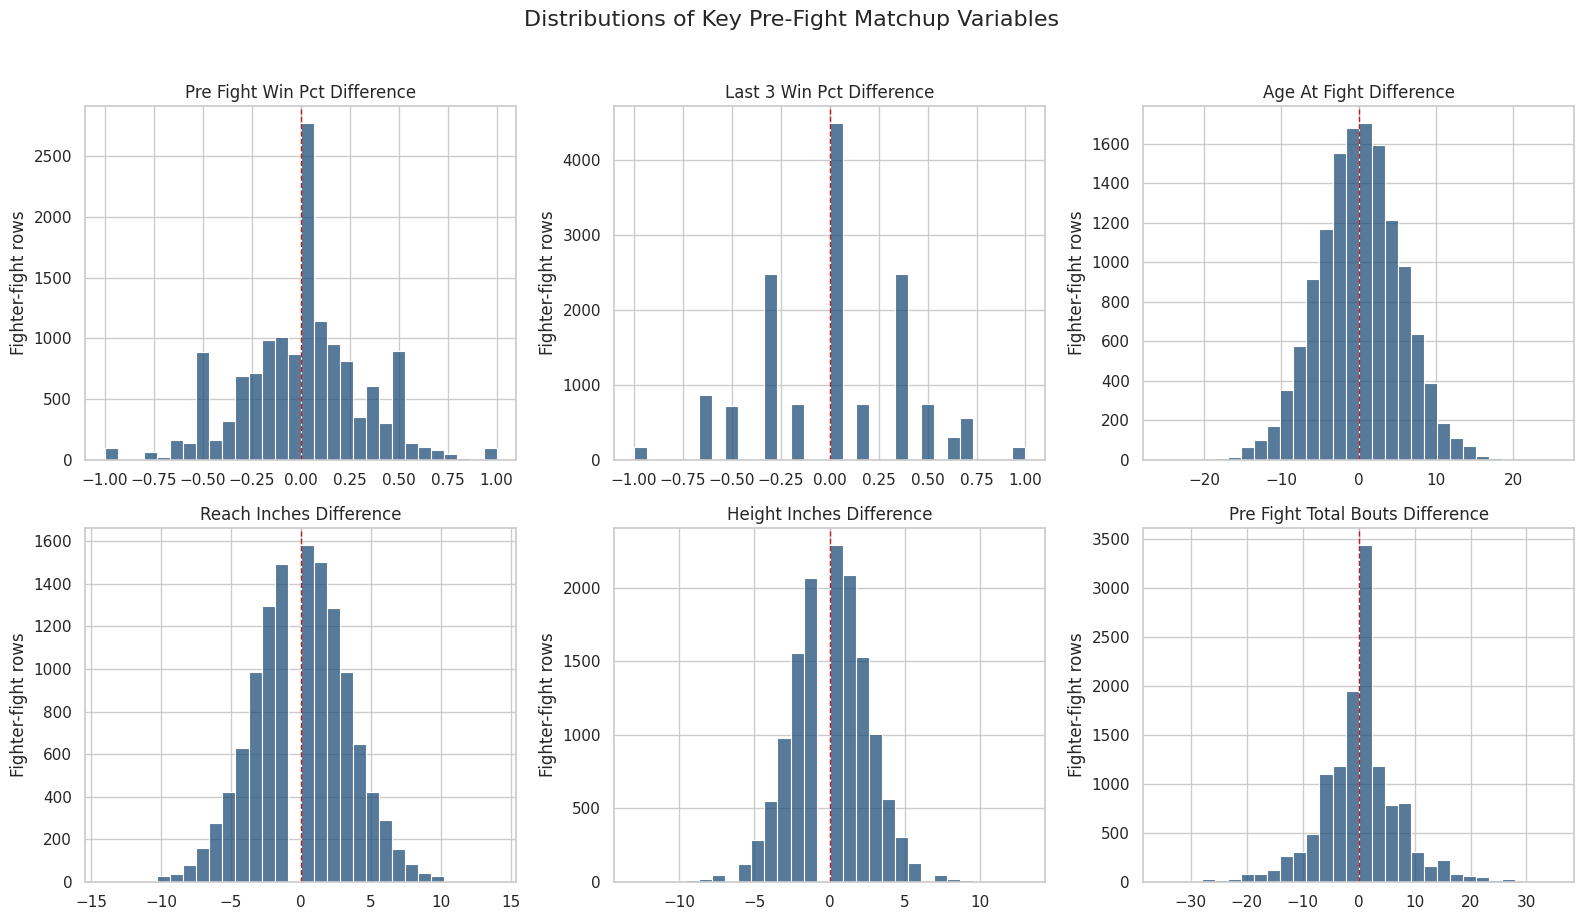

In [37]:
# 3.2 Histograms of numerical variables

sns.set_theme(style="whitegrid")

# Choose the main matchup variables for readable histograms
hist_cols = [
    "pre_fight_win_pct_difference",
    "last_3_win_pct_difference",
    "age_at_fight_difference",
    "reach_inches_difference",
    "height_inches_difference",
    "pre_fight_total_bouts_difference"
]

# Keep only columns that successfully exist in your table
hist_cols = [col for col in hist_cols if col in analysis_df.columns]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

axes = axes.flatten()

for ax, col in zip(axes, hist_cols):
    sns.histplot(
        data=analysis_df,
        x=col,
        bins=30,
        color="#1f4e79",
        edgecolor="white",
        ax=ax
    )

    ax.axvline(
        0,
        color="firebrick",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Fighter-fight rows")

# Hide unused panels
for ax in axes[len(hist_cols):]:
    ax.set_visible(False)

plt.suptitle(
    "Distributions of Key Pre-Fight Matchup Variables",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


Counts for: corner


,corner,count,percent
0,red,7676,53.0
1,blue,6801,47.0


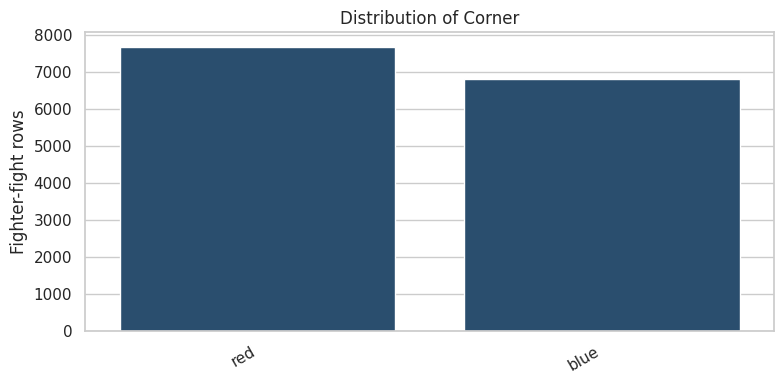


Counts for: stance


,stance,count,percent
0,Orthodox,10391,71.8
1,Southpaw,2820,19.5
2,Switch,799,5.5
3,Missing,446,3.1
4,OpenStance,18,0.1
5,Sideways,3,0.0


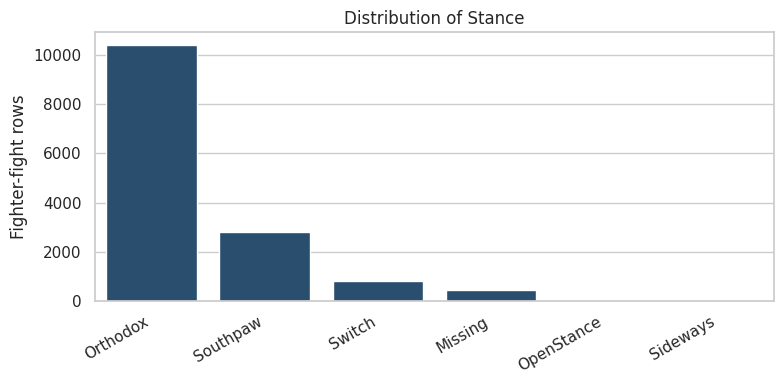

In [38]:
# 3.3 Counts of categorical variables
# Select categorical columns that exist in the final table
categorical_cols = [
    col for col in [
        "corner",
        "stance",
        "opponent_stance"
    ]
    if col in analysis_df.columns
]

for col in categorical_cols:
    print(f"\nCounts for: {col}")

    counts = (
        analysis_df[col]
        .fillna("Missing")
        .value_counts()
        .rename_axis(col)
        .reset_index(name="count")
    )

    counts["percent"] = (
        counts["count"] / counts["count"].sum() * 100
    ).round(1)

    display(counts)

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=analysis_df.fillna({col: "Missing"}),
        x=col,
        order=counts[col],
        color="#1f4e79"
    )

    plt.title(f"Distribution of {col.replace('_', ' ').title()}")
    plt.xlabel("")
    plt.ylabel("Fighter-fight rows")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

**Notes:** What do the distributions look like? Anything surprising or that needs cleaning back in Part 2?

# Part 4: Two Variables at a Time

Look at how pairs of variables relate, especially each candidate feature against the variable you want to predict.

| You want to... | Code |
|---|---|
| a scatter plot | `alt.Chart(df).mark_circle().encode(alt.X("a:Q", title="..."), alt.Y("b:Q", title="..."), alt.Color("group:N", title="..."))` |
| a scatter plot matrix | `alt.Chart(df).mark_circle().encode(alt.X(alt.repeat("column"), type="quantitative"), alt.Y(alt.repeat("row"), type="quantitative")).repeat(row=cols, column=cols)` |
| numerical vs. categorical | `alt.Chart(df).mark_boxplot().encode(alt.X("group:N"), alt.Y("value:Q"))` |
| correlations | `df.corr(numeric_only=True)`, `df[cols].corrwith(df["target"]).sort_values()` |

In [45]:
# 4.1 Scatter plots: observed win percentage by matchup advantage

def make_binned_win_rate(df, feature, bins=20):
    temp = df[[feature, "won_fight"]].dropna().copy()

    temp["bin"] = pd.cut(temp[feature], bins=bins)

    summary = (
        temp.groupby("bin", observed=True)
        .agg(
            win_pct=("won_fight", "mean"),
            n=("won_fight", "size")
        )
        .reset_index()
    )

    summary["midpoint"] = summary["bin"].apply(
        lambda interval: interval.mid
    )

    # Keep only JSON-safe numeric columns for Altair
    return summary[["midpoint", "win_pct", "n"]]


plot_cols = [
    "pre_fight_win_pct_difference",
    "last_3_win_pct_difference",
    "reach_inches_difference",
    "age_at_fight_difference"
]

plot_cols = [col for col in plot_cols if col in analysis_df.columns]

charts = []

for col in plot_cols:
    win_rate_data = make_binned_win_rate(analysis_df, col)

    chart = (
        alt.Chart(win_rate_data)
        .mark_line(point=True, color="#1f4e79")
        .encode(
            x=alt.X(
                "midpoint:Q",
                title="Fighter advantage over opponent"
            ),
            y=alt.Y(
                "win_pct:Q",
                title="Observed win percentage",
                scale=alt.Scale(domain=[0, 1]),
                axis=alt.Axis(format="%")
            ),
            tooltip=[
                alt.Tooltip("midpoint:Q", title="Matchup advantage", format=".2f"),
                alt.Tooltip("win_pct:Q", title="Win percentage", format=".1%"),
                alt.Tooltip("n:Q", title="Fighter-fight rows")
            ]
        )
        .properties(
            width=350,
            height=250,
            title=col.replace("_", " ").title()
        )
    )

    charts.append(chart)

# Arrange the four charts in a 2 x 2 layout
scatter_plots = (charts[0] | charts[1]) & (charts[2] | charts[3])

scatter_plots

alt.VConcatChart(...)

In [46]:
# 4.2 Correlations
# Keep numeric predictor columns only
numeric_cols = analysis_df.select_dtypes(include="number").columns.tolist()

# Remove IDs and odds from the initial fighter-history correlation analysis
exclude_cols = [
    "fight_id",
    "decimal_odds",
    "implied_prob"
]

numeric_cols = [
    col for col in numeric_cols
    if col not in exclude_cols
]

# Correlation matrix
correlation_matrix = analysis_df[numeric_cols].corr()

# Rank features by their correlation with winning
win_correlations = (
    correlation_matrix["won_fight"]
    .drop("won_fight")
    .sort_values(key=abs, ascending=False)
    .rename("correlation_with_win")
    .to_frame()
)

display(win_correlations.head(20).round(3))

,correlation_with_win
age_at_fight_difference,-0.164
pre_fight_win_pct_difference,0.143
age_at_fight,-0.119
last_3_win_pct_difference,0.118
pre_fight_td_landed_avg_difference,0.114
pre_fight_sig_str_ground_attempted_avg_difference,0.107
pre_fight_sig_str_ground_landed_avg_difference,0.106
opponent_age_at_fight,0.097
pre_fight_losses_difference,-0.094
pre_fight_td_attempted_avg_difference,0.090


**Notes:** Which relationships look strong, weak, or non-linear? Which variables look useful for predicting your target?

# Part 5: Compute Your Metrics

Compute the numbers your question depends on. Depending on your project, that may be group summaries, rates or ratios you derive, standardized scores, or distances and similarities between observations.

| You want to... | Code |
|---|---|
| summarize by group | `df.groupby("group")["col"].agg(["mean", "median", "std", "count"])` |
| a new derived column | `df.assign(rate=df["count"] / df["total"])` |
| standardize (z-scores) | `(df[cols] - df[cols].mean()) / df[cols].std()` |
| distances / similarities between rows | `from sklearn.metrics.pairwise import pairwise_distances, cosine_similarity` |
| text into numbers | `from sklearn.feature_extraction.text import TfidfVectorizer` |

In [ ]:
# 5.1

In [ ]:
# 5.2

**Notes:** What do these numbers tell you about your question?

# Part 6: Build and Test Models

Pick a **target** (`y`) and **features** (`X`). Start with a baseline, try more than one method, grade every model with **cross-validation on the same folds**, tune hyperparameters, and compare.

If your target is **categorical**, set up `X` and `y` now; the classification versions (`DummyClassifier`, `KNeighborsClassifier`, `LogisticRegression`, scored with accuracy) come in weeks 10 and 11.

| You want to... | Code |
|---|---|
| hold out a test set (optional "lockbox") | `X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)` |
| cross-validated RMSE | `np.sqrt(-cross_val_score(model, X, y, scoring="neg_mean_squared_error", cv=folds).mean())` |
| training RMSE | `np.sqrt(mean_squared_error(y, model.fit(X, y).predict(X)))` |
| one-hot encode + scale inside a model | `make_pipeline(make_column_transformer((OneHotEncoder(sparse_output=False), cat_cols), (StandardScaler(), num_cols)), KNeighborsRegressor())` |
| grid search | `GridSearchCV(model, param_grid={"kneighborsregressor__n_neighbors": range(1, 31)}, scoring="neg_mean_squared_error", cv=folds).fit(X, y)` |
| read a grid search | `.best_params_`, `np.sqrt(-.best_score_)`, `pd.DataFrame(.cv_results_)` |

In [ ]:
# Use these folds for every cross-validation, so your scores are comparable.
folds = KFold(n_splits=5, shuffle=True, random_state=0)

In [ ]:
# 6.1 Target (y) and features (X)

In [ ]:
# 6.2 Baseline

In [ ]:
# 6.3 Model 1

In [ ]:
# 6.4 Model 2

In [ ]:
# 6.5 Tune hyperparameters

In [ ]:
# 6.6 Compare: one table and one Altair chart of CV RMSE for every model (baseline included)

**Notes:** Which model would you recommend, and how much better than the baseline is it? What would you try next?

# Part 7: Where You Are

**Notes:** What have you learned so far? What still needs work, and who is doing it? What do you need help with?

## Submission Instructions

To share this notebook (for example, as proof of your preliminary work), export it as an **HTML file**. No PDF conversion needed.

- Restart this notebook and run the cells from beginning to end.
  - Go to Runtime > Restart session and run all.
  - Make sure every cell ran without errors and every chart appears.
- Run the cell below. It downloads this notebook as a webpage, `_NOTEBOOK.html`.

In [ ]:
# @markdown Run this cell to download this notebook as a webpage, `_NOTEBOOK.html`.

import google, json, nbformat

# Get the current notebook and write it to _NOTEBOOK.ipynb
raw_notebook = google.colab._message.blocking_request("get_ipynb",
                                                      timeout_sec=30)["ipynb"]
with open("_NOTEBOOK.ipynb", "w", encoding="utf-8") as ipynb_file:
  ipynb_file.write(json.dumps(raw_notebook))

# Use nbconvert to convert .ipynb to .html.
!jupyter nbconvert --to html --log-level WARN _NOTEBOOK.ipynb

# Download the .html file.
google.colab.files.download("_NOTEBOOK.html")

- Open `_NOTEBOOK.html` in your browser and check that all of your code, output, written answers, and charts are there. (The charts load from the internet, so you need to be online for them to appear.)